In [3]:
import pm4py

In [1]:
import pandas as pd

def import_csv(file_path):
    event_log = pd.read_csv(file_path, sep=';')
    num_events = len(event_log)
    num_cases = len(event_log.case_id.unique())
    print(f'Number of events: {num_events}\nNumber of cases: {num_cases}')

import_csv('./running-example.csv')

Number of events: 42
Number of cases: 6


In [4]:
def import_csv(file_path):
    event_log = pd.read_csv(file_path, sep=';')
    event_log = pm4py.format_dataframe(event_log, case_id='case_id', activity_key='activity', timestamp_key='timestamp')
    start_activities = pm4py.get_start_activities(event_log)
    end_activities = pm4py.get_end_activities(event_log)
    print(f'start act: {start_activities}\nEnd_act: {end_activities}')
import_csv('./running-example.csv')

start act: {'register request': 6}
End_act: {'reject request': 3, 'pay compensation': 3}


c:\Users\ytran\Documents\repos\eventLogSimulation\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
parsing log, completed traces :: 100%|██████████| 6/6 [00:00<?, ?it/s]


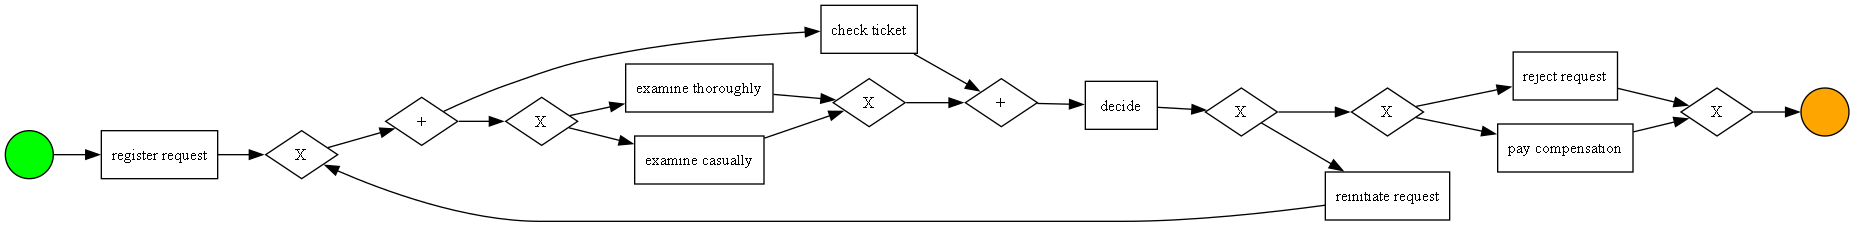

In [5]:
log = pm4py.read_xes('./running-example.xes.xml')
process_tree = pm4py.discover_process_tree_inductive(log)
bpmn_model = pm4py.convert_to_bpmn(process_tree)
pm4py.view_bpmn(bpmn_model)

In [1]:
### Explore real event logs 
import pm4py
log_file = './RequestForPayment.xes'
log =pm4py.read_xes(log_file)
total_events = len(log)


c:\Users\ytran\Documents\repos\eventLogSimulation\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
parsing log, completed traces :: 100%|██████████| 6886/6886 [00:01<00:00, 3481.88it/s]


In [5]:
log.columns

Index(['id', 'org:resource', 'concept:name', 'time:timestamp', 'org:role',
       'case:Rfp_id', 'case:Project', 'case:Task', 'case:concept:name',
       'case:OrganizationalEntity', 'case:Cost Type', 'case:RequestedAmount',
       'case:Activity', 'case:RfpNumber'],
      dtype='object')

In [3]:
log[:5525]

,id,org:resource,concept:name,time:timestamp,org:role,case:Rfp_id,case:Project,case:Task,case:concept:name,case:OrganizationalEntity,case:Cost Type,case:RequestedAmount,case:Activity,case:RfpNumber
0,st_step 148220_0,STAFF MEMBER,Request For Payment SUBMITTED by EMPLOYEE,2017-01-09 09:17:18+00:00,EMPLOYEE,request for payment 148214,project 148216,UNKNOWN,request for payment 148214,organizational unit 65463,0,34.336343,UNKNOWN,request for payment number 148215
1,st_step 148221_0,STAFF MEMBER,Request For Payment FINAL_APPROVED by SUPERVISOR,2017-01-09 09:18:00+00:00,SUPERVISOR,request for payment 148214,project 148216,UNKNOWN,request for payment 148214,organizational unit 65463,0,34.336343,UNKNOWN,request for payment number 148215
2,st_step 148222_0,STAFF MEMBER,Request For Payment REJECTED by MISSING,2017-01-10 12:42:32+00:00,MISSING,request for payment 148214,project 148216,UNKNOWN,request for payment 148214,organizational unit 65463,0,34.336343,UNKNOWN,request for payment number 148215
3,st_step 148219_0,STAFF MEMBER,Request For Payment SUBMITTED by EMPLOYEE,2017-03-03 09:51:13+00:00,EMPLOYEE,request for payment 148214,project 148216,UNKNOWN,request for payment 148214,organizational unit 65463,0,34.336343,UNKNOWN,request for payment number 148215
4,st_step 148218_0,STAFF MEMBER,Request For Payment APPROVED by PRE_APPROVER,2017-03-03 09:51:42+00:00,PRE_APPROVER,request for payment 148214,project 148216,UNKNOWN,request for payment 148214,organizational unit 65463,0,34.336343,UNKNOWN,request for payment number 148215
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5520,st_step 157990_0,STAFF MEMBER,Request For Payment APPROVED by ADMINISTRATION,2018-01-11 15:15:12+00:00,ADMINISTRATION,request for payment 157986,project 503,task 156487,request for payment 157986,organizational unit 65456,0,41.066091,activity 505,request for payment number 157987
5521,st_step 157988_0,STAFF MEMBER,Request For Payment FINAL_APPROVED by SUPERVISOR,2018-01-15 10:27:19+00:00,SUPERVISOR,request for payment 157986,project 503,task 156487,request for payment 157986,organizational unit 65456,0,41.066091,activity 505,request for payment number 157987
5522,rp_request for payment 157986_15,SYSTEM,Request Payment,2018-01-15 22:36:07+00:00,UNDEFINED,request for payment 157986,project 503,task 156487,request for payment 157986,organizational unit 65456,0,41.066091,activity 505,request for payment number 157987
5523,rp_request for payment 157986_16,SYSTEM,Payment Handled,2018-01-18 17:31:10+00:00,UNDEFINED,request for payment 157986,project 503,task 156487,request for payment 157986,organizational unit 65456,0,41.066091,activity 505,request for payment number 157987


In [2]:
import numpy as np

all_cases = log['case:Rfp_id'].unique()
ave_case_len = 0
shortest_case = np.inf
shortes_case_idx = 0
longest_case = 0
logest_case_idx = 0
for i, case in enumerate(all_cases):
    case_df = log[log['case:Rfp_id'] == case]
    ave_case_len = (ave_case_len*i + len(case_df))/(i+1)
    if len(case_df) > longest_case:
        longest_case = len(case_df)
        longest_case_idx = i
    if len(case_df) < shortest_case:
        shortest_case = len(case_df)
        shortes_case_idx = i

print(f'ave case len: {ave_case_len}')
print(f'Longest case len is {longest_case} at index {longest_case_idx}')
print(f'Shorted case len is {shortest_case} at index {shortes_case_idx}')


ave case len: 5.343595701423179
Longest case len is 20 at index 5525
Shorted case len is 1 at index 179


In [28]:
payment_5525_df = log[log['case:Rfp_id'] == all_cases[1]]
payment_5525_df.sort_values(by='time:timestamp')
payment_5525_df


,id,org:resource,concept:name,time:timestamp,org:role,case:Rfp_id,case:Project,case:Task,case:concept:name,case:OrganizationalEntity,case:Cost Type,case:RequestedAmount,case:Activity,case:RfpNumber
8,st_step 149293_0,STAFF MEMBER,Request For Payment SUBMITTED by EMPLOYEE,2017-01-09 10:30:48+00:00,EMPLOYEE,request for payment 149290,project 147843,UNKNOWN,request for payment 149290,organizational unit 65458,0,15.182428,UNKNOWN,request for payment number 149291
9,st_step 149292_0,STAFF MEMBER,Request For Payment FINAL_APPROVED by SUPERVISOR,2017-01-09 10:31:42+00:00,SUPERVISOR,request for payment 149290,project 147843,UNKNOWN,request for payment 149290,organizational unit 65458,0,15.182428,UNKNOWN,request for payment number 149291
10,rp_request for payment 149290_15,SYSTEM,Request Payment,2017-01-10 10:52:03+00:00,UNDEFINED,request for payment 149290,project 147843,UNKNOWN,request for payment 149290,organizational unit 65458,0,15.182428,UNKNOWN,request for payment number 149291
11,rp_request for payment 149290_16,SYSTEM,Payment Handled,2017-01-12 17:31:32+00:00,UNDEFINED,request for payment 149290,project 147843,UNKNOWN,request for payment 149290,organizational unit 65458,0,15.182428,UNKNOWN,request for payment number 149291


In [25]:
all_activities = log['concept:name'].unique()
for act in all_activities:
    print(act)

Request For Payment SUBMITTED by EMPLOYEE
Request For Payment FINAL_APPROVED by SUPERVISOR
Request For Payment REJECTED by MISSING
Request For Payment APPROVED by PRE_APPROVER
Request Payment
Payment Handled
Request For Payment REJECTED by SUPERVISOR
Request For Payment REJECTED by EMPLOYEE
Request For Payment APPROVED by SUPERVISOR
Request For Payment FINAL_APPROVED by DIRECTOR
Request For Payment REJECTED by PRE_APPROVER
Request For Payment SAVED by EMPLOYEE
Request For Payment REJECTED by ADMINISTRATION
Request For Payment APPROVED by ADMINISTRATION
Request For Payment APPROVED by BUDGET OWNER
Request For Payment REJECTED by BUDGET OWNER
Request For Payment FOR_APPROVAL by ADMINISTRATION
Request For Payment FINAL_APPROVED by BUDGET OWNER
Request For Payment FOR_APPROVAL by SUPERVISOR
